# ATLAS — USGS 3DEP acquisition and terrain features

Adapted from `USGS_3DEP_EDA.py`. **USGS only — not NAIP.** Run from the ATLAS repository root with your WSL kernel. Default is a five-facility test. USGS 3DEP ImageServer returns an elevation mosaic; the 1 m product catalog search is supplementary and **does not prove** the exported mosaic has 1 m native resolution. No Earth Engine credentials required.

Outputs: `Data/processed/usgs_image_manifest.csv`, `Data/processed/usgs_terrain_features.csv`, and local GeoTIFFs in `Data/raw/usgs_3dep/`. No labels are inferred.

## 1. Imports and configuration

In [18]:
from pathlib import Path
import json, os, time
import numpy as np
import pandas as pd
import requests
import rasterio
from rasterio.io import MemoryFile
from pyproj import Transformer
import matplotlib.pyplot as plt

REGISTRY = Path("Data/processed/im3_facility_registry.csv")
OUT_DIR = Path("Data/raw/usgs_3dep")
PROCESSED = Path("Data/processed")
MANIFEST_PATH = PROCESSED / "usgs_image_manifest.csv"
FEATURE_PATH = PROCESSED / "usgs_terrain_features.csv"
OUT_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED.mkdir(parents=True, exist_ok=True)

TEST_LIMIT = 25  # Change to None only after validating the five-facility test
PATCH_SIZE_M = 1000  # 1 km square around facility
PIXEL_SIZE_M = 10  # Requested output sampling, NOT guaranteed native source resolution
REQUEST_TIMEOUT = 90
EXPORT_URL = "https://elevation.nationalmap.gov/arcgis/rest/services/3DEPElevation/ImageServer/exportImage"
EPQS_URL = "https://epqs.nationalmap.gov/v1/json"
TNM_URL = "https://tnmaccess.nationalmap.gov/api/v1/products"


## 2. Load IM3 and preserve identifiers

In [19]:
registry = pd.read_csv(REGISTRY, dtype={"id": "string"})

# Standardize IM3 identifier
registry = registry.rename(columns={"id": "facility_id"})

# Validate required columns
required = {"facility_id", "lat", "lon"}
assert required.issubset(registry.columns), \
    f"Missing: {required - set(registry.columns)}"

# Validate facility IDs
assert registry.facility_id.notna().all()
assert registry.facility_id.is_unique

# Validate coordinates
registry["lat"] = pd.to_numeric(registry["lat"], errors="coerce")
registry["lon"] = pd.to_numeric(registry["lon"], errors="coerce")

assert registry.lat.between(-90, 90).all()
assert registry.lon.between(-180, 180).all()

print("Facilities:", len(registry))
display(registry[["facility_id", "lat", "lon"]].head())

Facilities: 1240


,facility_id,lat,lon
0,0002744301,40.544256,-74.496521
1,0007805491,40.100657,-82.814358
2,0009474864,35.894738,-81.546515
3,0013924557,41.515955,-93.711719
4,0014593270,35.588771,-81.261809


## 3. Functions — coordinate system, EPQS, and optional 1 m catalog search

In [20]:
def get_utm_epsg(lat, lon):
    zone = max(1, min(60, int((lon + 180) / 6) + 1))
    return (32600 if lat >= 0 else 32700) + zone

def epqs_elevation(session, lat, lon):
    r = session.get(EPQS_URL, params={"x": lon, "y": lat, "wkid": 4326,
                                      "units": "Meters", "includeDate": True}, timeout=REQUEST_TIMEOUT)
    r.raise_for_status()
    payload = r.json()
    val = payload.get("value")
    try:
        elevation = float(val)
        if not np.isfinite(elevation) or elevation <= -9999:
            elevation = np.nan
    except (TypeError, ValueError):
        elevation = np.nan
    return elevation, payload

def search_1m_products(session, lat, lon, delta=0.01):
    bbox = [lon-delta, lat-delta, lon+delta, lat+delta]
    r = session.get(TNM_URL, params={"bbox": ",".join(map(str,bbox)),
                "datasets": "Digital Elevation Model (DEM) 1 meter",
                "outputFormat": "JSON", "max": 20}, timeout=REQUEST_TIMEOUT)
    r.raise_for_status()
    return r.json()


## 4. Export a projected DEM GeoTIFF and validate the response

We request a fixed **1 km × 1 km** area in local UTM coordinates. A requested 10 m output grid is not evidence of 10 m native DEM resolution. Never interpret resampled pixels as new terrain detail.

In [21]:
def download_dem(session, facility_id, lat, lon):
    epsg = get_utm_epsg(lat, lon)
    cx, cy = Transformer.from_crs("EPSG:4326", f"EPSG:{epsg}", always_xy=True).transform(lon, lat)
    half = PATCH_SIZE_M / 2
    bbox = (cx-half, cy-half, cx+half, cy+half)
    pixels = int(round(PATCH_SIZE_M / PIXEL_SIZE_M))
    path = OUT_DIR / f"{facility_id}_dem_utm.tif"
    params = {"bbox": ",".join(map(str,bbox)), "bboxSR": epsg, "imageSR": epsg,
              "size": f"{pixels},{pixels}", "format": "tiff", "pixelType": "F32",
              "interpolation": "RSP_BilinearInterpolation", "f": "image"}
    r = session.get(EXPORT_URL, params=params, timeout=REQUEST_TIMEOUT)
    r.raise_for_status()
    # Validate bytes BEFORE writing; ArcGIS can return JSON errors with HTTP 200.
    with MemoryFile(r.content) as mem:
        with mem.open() as src:
            if src.count != 1 or src.crs is None or src.width != pixels or src.height != pixels:
                raise ValueError("Unexpected raster dimensions/bands/CRS")
            if src.crs.to_epsg() != epsg:
                raise ValueError(f"Unexpected raster CRS: {src.crs}")
            array = src.read(1, masked=True)
            if array.count() == 0:
                raise ValueError("Raster has no valid elevation pixels")
    tmp = path.with_suffix(".part")
    tmp.write_bytes(r.content)
    os.replace(tmp, path)
    return path, epsg, bbox


## 5. Terrain features — mask NoData and avoid gradients across missing pixels

In [22]:
def extract_features(path):
    with rasterio.open(path) as src:
        a = src.read(1, masked=True).astype("float64")
        z = a.filled(np.nan)
        valid = np.isfinite(z)
        if not valid.any():
            raise ValueError("No valid DEM pixels")
        xres, yres = map(abs, src.res)
        # Central differences; gradients are invalid where a neighbor is missing.
        dzdy, dzdx = np.gradient(np.where(valid, z, np.nan), yres, xres)
        slope = np.degrees(np.arctan(np.hypot(dzdx, dzdy)))
        good_slope = slope[np.isfinite(slope)]
        vals = z[valid]
        return {
            "dem_mean_elevation_m": float(vals.mean()),
            "dem_std_elevation_m": float(vals.std()),
            "dem_min_elevation_m": float(vals.min()),
            "dem_max_elevation_m": float(vals.max()),
            "dem_elevation_range_m": float(vals.max()-vals.min()),
            "dem_mean_slope_deg": float(good_slope.mean()) if good_slope.size else np.nan,
            "dem_p95_slope_deg": float(np.percentile(good_slope,95)) if good_slope.size else np.nan,
            "dem_valid_fraction": float(valid.mean()),
            "dem_pixel_size_m": float((xres+yres)/2),
        }


## 6. Initialize or resume manifests

Existing successful records are preserved; only a matching, readable GeoTIFF with existing feature values is skipped. Failures remain retryable.

In [23]:
base = registry[["facility_id", "lat", "lon"]].copy()
for col, default in {"download_status":"pending", "local_dem_path":pd.NA, "utm_epsg":pd.NA,
                     "requested_bbox_utm":pd.NA, "epqs_elevation_m":np.nan,
                     "one_meter_catalog_count":pd.NA, "error_message":pd.NA}.items():
    base[col] = default
if MANIFEST_PATH.exists():
    previous = pd.read_csv(MANIFEST_PATH, dtype={"facility_id":"string"})
    assert previous.facility_id.is_unique
    # Keep current registry as source of truth for coordinates; restore progress columns.
    for col in base.columns.difference(["facility_id", "lat", "lon"]):
        if col in previous:
            base[col] = base.facility_id.map(previous.set_index("facility_id")[col])
manifest = base.copy()
features = (pd.read_csv(FEATURE_PATH, dtype={"facility_id":"string"})
            if FEATURE_PATH.exists() else pd.DataFrame(columns=["facility_id"]))
assert features.facility_id.is_unique
print(manifest.download_status.value_counts(dropna=False))


download_status
pending    1235
success       5
Name: count, dtype: int64


## 7. Run five-facility acquisition test

Set `RUN_DOWNLOADS = True` to begin network requests. Keep the five-facility limit until you inspect the output. The optional catalog query is disabled by default because it is not necessary to extract features from the elevation service.

In [24]:
RUN_DOWNLOADS = True  # Change to True when ready
QUERY_EPQS = True
QUERY_1M_CATALOG = False

subset = registry if TEST_LIMIT is None else registry.head(TEST_LIMIT)

def save_progress():
    assert manifest.facility_id.is_unique and len(manifest) == len(registry)
    for frame, target in [(manifest, MANIFEST_PATH), (features, FEATURE_PATH)]:
        temp = target.with_suffix(".tmp")
        frame.to_csv(temp, index=False)
        os.replace(temp, target)

if RUN_DOWNLOADS:
    with requests.Session() as session:
        for _, row in subset.iterrows():
            fid, lat, lon = str(row.facility_id), float(row.lat), float(row.lon)
            idx = manifest.index[manifest.facility_id == fid][0]
            old_path = manifest.at[idx, "local_dem_path"]
            already_has_features = fid in set(features.facility_id.astype(str))
            if (manifest.at[idx, "download_status"] == "success" and
                isinstance(old_path, str) and Path(old_path).is_file() and already_has_features):
                try:
                    with rasterio.open(old_path) as src:
                        if src.count == 1 and src.read(1, masked=True).count() > 0:
                            print("Skipping:", fid)
                            continue
                except Exception:
                    pass
            try:
                point_val = np.nan
                if QUERY_EPQS:
                    point_val, _ = epqs_elevation(session, lat, lon)
                count = pd.NA
                if QUERY_1M_CATALOG:
                    count = search_1m_products(session, lat, lon).get("total")
                path, epsg, bbox = download_dem(session, fid, lat, lon)
                vals = extract_features(path)
                record = {"facility_id": fid, **vals}
                features = pd.concat([features[features.facility_id != fid],
                                      pd.DataFrame([record])], ignore_index=True)
                for col, value in {"download_status":"success", "local_dem_path":str(path),
                                   "utm_epsg":epsg, "requested_bbox_utm":json.dumps(bbox),
                                   "epqs_elevation_m":point_val, "one_meter_catalog_count":count,
                                   "error_message":pd.NA}.items():
                    manifest.at[idx,col] = value
                print("Success:", fid)
            except Exception as exc:
                manifest.at[idx,"download_status"] = "failed"
                manifest.at[idx,"error_message"] = f"{type(exc).__name__}: {exc}"[:400]
                print("Failed:", fid, manifest.at[idx,"error_message"])
            finally:
                save_progress()
            time.sleep(0.5)
else:
    print("Dry run: no network requests. Set RUN_DOWNLOADS=True to test five facilities.")


Skipping: 0002744301
Skipping: 0007805491
Skipping: 0009474864
Skipping: 0013924557
Skipping: 0014593270
Success: 0014930068
Success: 0014997588
Success: 0015884451
Success: 0016282459
Success: 0018518989
Success: 0025706343
Success: 0028544618
Success: 0029827954
Success: 0030666790
Success: 0031250931
Success: 0031800424
Success: 0032560290
Success: 0032560292
Success: 0034770750
Success: 0035491576
Success: 0036897140
Success: 0037947313
Success: 0037947314
Success: 0037947315
Success: 0038305431


## 8. Inspect results and visualize one downloaded facility

download_status
pending    1215
success      25
Name: count, dtype: int64


,facility_id,lat,lon,download_status,local_dem_path,utm_epsg,requested_bbox_utm,epqs_elevation_m,one_meter_catalog_count,error_message
0,0002744301,40.544256,-74.496521,success,Data/raw/usgs_3dep/0002744301_dem_utm.tif,32618.0,"[542133.7591965924, 4487788.87831136, 543133.7...",23.110586,NaN,NaN
1,0007805491,40.100657,-82.814358,success,Data/raw/usgs_3dep/0007805491_dem_utm.tif,32617.0,"[344850.1275400361, 4440006.789549236, 345850....",312.346222,NaN,NaN
2,0009474864,35.894738,-81.546515,success,Data/raw/usgs_3dep/0009474864_dem_utm.tif,32617.0,"[450178.3352245505, 3971911.3432104047, 451178...",363.159302,NaN,NaN
3,0013924557,41.515955,-93.711719,success,Data/raw/usgs_3dep/0013924557_dem_utm.tif,32615.0,"[440112.3817676772, 4595779.987757711, 441112....",290.950684,NaN,NaN
4,0014593270,35.588771,-81.261809,success,Data/raw/usgs_3dep/0014593270_dem_utm.tif,32617.0,"[475781.87686115154, 3937870.2867834917, 47678...",268.252716,NaN,NaN
5,0014930068,35.049942,-106.542822,success,Data/raw/usgs_3dep/0014930068_dem_utm.tif,32613.0,"[358794.6915900193, 3879169.5588749866, 359794...",1653.987305,NaN,NaN
6,0014997588,37.482763,-77.236455,success,Data/raw/usgs_3dep/0014997588_dem_utm.tif,32618.0,"[301760.9873315103, 4150278.162512235, 302760....",43.855167,NaN,NaN
7,0015884451,40.643753,-74.285481,success,Data/raw/usgs_3dep/0015884451_dem_utm.tif,32618.0,"[559914.7519958852, 4498956.8710962, 560914.75...",18.591848,NaN,NaN
8,0016282459,39.140242,-76.606431,success,Data/raw/usgs_3dep/0016282459_dem_utm.tif,32618.0,"[360667.59169759986, 4333068.240701358, 361667...",16.548042,NaN,NaN
9,0018518989,34.844123,-86.628423,success,Data/raw/usgs_3dep/0018518989_dem_utm.tif,32616.0,"[533471.2532900355, 3855320.0867307507, 534471...",269.188965,NaN,NaN


,facility_id,dem_mean_elevation_m,dem_std_elevation_m,dem_min_elevation_m,dem_max_elevation_m,dem_elevation_range_m,dem_mean_slope_deg,dem_p95_slope_deg,dem_valid_fraction,dem_pixel_size_m
0,0002744301,21.135401,2.616918,13.530478,26.226437,12.695959,1.743347,4.266691,1.0,10.0
1,0007805491,311.665009,3.340322,303.405609,320.044678,16.639069,1.674182,4.541862,1.0,10.0
2,0009474864,352.227976,18.173733,322.828735,403.115845,80.287109,8.385094,18.187010,1.0,10.0
3,0013924557,291.503840,3.162098,280.969452,297.112305,16.142853,2.697844,6.806389,1.0,10.0
4,0014593270,269.856182,8.967045,248.996140,287.959534,38.963394,5.082926,10.638708,1.0,10.0


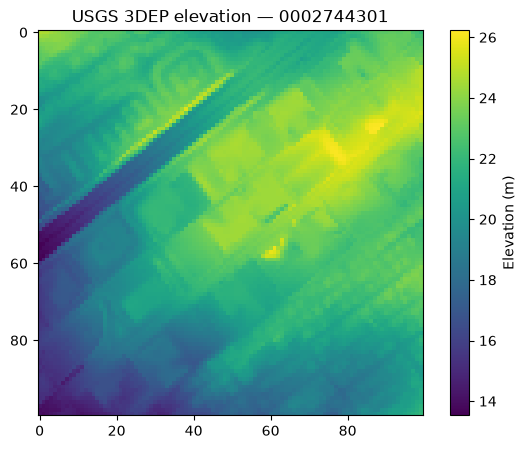

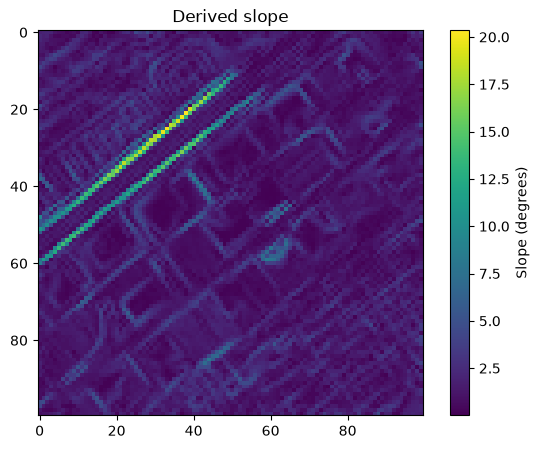

In [25]:
print(manifest.download_status.value_counts(dropna=False))
display(manifest.head(25))
display(features.head())

successful = manifest[manifest.download_status == "success"]
if len(successful):
    p = Path(successful.iloc[0].local_dem_path)
    with rasterio.open(p) as src:
        z = src.read(1, masked=True).astype("float64").filled(np.nan)
        dy, dx = np.gradient(z, abs(src.res[1]), abs(src.res[0]))
        slope = np.degrees(np.arctan(np.hypot(dx,dy)))
    plt.figure(figsize=(7,5)); plt.imshow(z); plt.colorbar(label="Elevation (m)")
    plt.title(f"USGS 3DEP elevation — {successful.iloc[0].facility_id}"); plt.show()
    plt.figure(figsize=(7,5)); plt.imshow(slope); plt.colorbar(label="Slope (degrees)")
    plt.title("Derived slope"); plt.show()
else:
    print("No successful downloads yet; visualization skipped.")


## 9. Handoff and limitations

- Join `usgs_terrain_features.csv` to IM3 using `facility_id` (string); validate `one_to_one`.
- A GeoTIFF exported by the 3DEP ImageServer is a **resampled elevation service output**, not necessarily an original 1 m 3DEP source tile. The optional TNM 1 m catalog query only reports candidates, not verified coverage/resolution.
- Acquisition dates are **not inferred** from EPQS or product search; obtaining authoritative raster source provenance requires additional work.
- Requested 1 km crops need not match NAIP's footprint until the team agrees on a shared region definition.
- The notebook does not download RGB/NAIP imagery and does not require Earth Engine.
- Test five facilities before increasing `TEST_LIMIT`; large batches may hit service limits.


## final validation

In [26]:
import rasterio
import numpy as np

dem_path = "Data/raw/usgs_3dep/0002744301_dem_utm.tif"

with rasterio.open(dem_path) as src:
    elevation = src.read(1, masked=True)

    print("CRS:", src.crs)
    print("Resolution:", src.res)
    print("Dimensions:", src.width, "x", src.height)
    print("Bands:", src.count)
    print("Valid pixel percentage:",
          round(elevation.count() / elevation.size * 100, 2))
    print("Elevation range:",
          float(elevation.min()),
          "to",
          float(elevation.max()))

CRS: EPSG:32618
Resolution: (10.0, 10.0)
Dimensions: 100 x 100
Bands: 1
Valid pixel percentage: 100.0
Elevation range: 13.530477523803711 to 26.226436614990234


## checks on manifest and extracted features

In [27]:
print("Manifest records:", len(manifest))
print("\nDownload statuses:")
print(manifest["download_status"].value_counts(dropna=False))

print("\nTerrain feature records:", len(features))

print("\nFeature columns:")
print(features.columns.tolist())

Manifest records: 1240

Download statuses:
download_status
pending    1215
success      25
Name: count, dtype: int64

Terrain feature records: 25

Feature columns:
['facility_id', 'dem_mean_elevation_m', 'dem_std_elevation_m', 'dem_min_elevation_m', 'dem_max_elevation_m', 'dem_elevation_range_m', 'dem_mean_slope_deg', 'dem_p95_slope_deg', 'dem_valid_fraction', 'dem_pixel_size_m']


## check on save

In [28]:
from pathlib import Path

print("Manifest CSVs:")
print(list(Path("Data/processed").glob("*usgs*manifest*.csv")))

print("\nFeature CSVs:")
print(list(Path("Data/processed").glob("*usgs*feature*.csv")))

print("\nDownloaded GeoTIFFs:")
print(len(list(Path("Data/raw/usgs_3dep").glob("*.tif"))))

Manifest CSVs:
[PosixPath('Data/processed/usgs_image_manifest.csv')]

Feature CSVs:
[PosixPath('Data/processed/usgs_terrain_features.csv')]

Downloaded GeoTIFFs:
29


## check for next batch

In [29]:
queue = manifest[
    manifest["download_status"].isin(["pending", "failed"])
].head(25)

print("Facilities in next batch:", len(queue))
print("Previously successful facilities included:",
      queue["facility_id"].isin(
          manifest.loc[
              manifest["download_status"] == "success",
              "facility_id"
          ]
      ).sum())

Facilities in next batch: 25
Previously successful facilities included: 0


## identifying the 4 extra files

In [31]:
from pathlib import Path

usgs_dir = Path("Data/raw/usgs_3dep")

for path in sorted(usgs_dir.glob("*.tif")):
    print(path.name)


# check for untracked geotiffs
from pathlib import Path
import pandas as pd

usgs_dir = Path("Data/raw/usgs_3dep")

# Actual files
actual_files = {p.name for p in usgs_dir.glob("*.tif")}

# Files referenced by successful manifest records
tracked_files = {
    Path(p).name
    for p in manifest.loc[
        manifest["download_status"] == "success",
        "local_image_path"
    ].dropna()
}

extra_files = actual_files - tracked_files

print("Files on disk:", len(actual_files))
print("Tracked successful files:", len(tracked_files))
print("Untracked files:", len(extra_files))
print(sorted(extra_files))

0002744301_dem_utm.tif
0007805491_dem_utm.tif
0009474864_dem_utm.tif
0013924557_dem_utm.tif
0014593270_dem_utm.tif
0014930068_dem_utm.tif
0014997588_dem_utm.tif
0015884451_dem_utm.tif
0016282459_dem_utm.tif
0018518989_dem_utm.tif
0025706343_dem_utm.tif
0028544618_dem_utm.tif
0029827954_dem_utm.tif
0030666790_dem_utm.tif
0031250931_dem_utm.tif
0031800424_dem_utm.tif
0032560290_dem_utm.tif
0032560292_dem_utm.tif
0034770750_dem_utm.tif
0035491576_dem_utm.tif
0036897140_dem_utm.tif
0037947313_dem_utm.tif
0037947314_dem_utm.tif
0037947315_dem_utm.tif
0038305431_dem_utm.tif
TEST_LOCATION_dem.tif
TEST_LOCATION_dem_utm.tif
test_dem.tif
test_dem_utm.tif


KeyError: 'local_image_path'

## moving the fouor files

In [34]:
from pathlib import Path
import shutil

usgs_dir = Path("Data/raw/usgs_3dep")
eda_dir = usgs_dir / "eda_samples"

eda_files = [
    "TEST_LOCATION_dem.tif",
    "TEST_LOCATION_dem_utm.tif",
    "test_dem.tif",
    "test_dem_utm.tif"
]

eda_dir.mkdir(parents=True, exist_ok=True)

for filename in eda_files:
    source = usgs_dir / filename
    destination = eda_dir / filename

    if source.exists():
        shutil.move(str(source), str(destination))
        print(f"Moved: {filename}")

# verify cleanup
production_files = list(usgs_dir.glob("*_dem_utm.tif"))
eda_files = list(eda_dir.glob("*.tif"))

print("Production GeoTIFFs:", len(production_files))
print("EDA GeoTIFFs:", len(eda_files))
print(manifest.columns.tolist())

Production GeoTIFFs: 25
EDA GeoTIFFs: 4
['facility_id', 'lat', 'lon', 'download_status', 'local_dem_path', 'utm_epsg', 'requested_bbox_utm', 'epqs_elevation_m', 'one_meter_catalog_count', 'error_message']


## check download status

In [35]:
print(manifest["download_status"].value_counts(dropna=False))

# check manifest paths
from pathlib import Path

tracked_files = {
    Path(p).name
    for p in manifest["local_dem_path"].dropna()
    if str(p).strip()
}

actual_files = {
    p.name
    for p in Path("Data/raw/usgs_3dep").glob("*_dem_utm.tif")
}

print("Tracked files:", len(tracked_files))
print("Production files:", len(actual_files))
print("Untracked files:", actual_files - tracked_files)
print("Missing files:", tracked_files - actual_files)

download_status
pending    1215
success      25
Name: count, dtype: int64
Tracked files: 25
Production files: 25
Untracked files: set()
Missing files: set()


## verify downloaded terrain features

In [36]:
print("Terrain feature records:", len(features))
print("Unique facilities:", features["facility_id"].nunique())
print("Duplicate IDs:", features["facility_id"].duplicated().sum())

Terrain feature records: 25
Unique facilities: 25
Duplicate IDs: 0
